# TP Jour 4 — Tests d'Hypothèses Statistiques, Segmentation & Restitution BI

### Objectifs de la séance
1. Valider scientifiquement deux hypothèses métier sur votre dataset à l'aide de **tests statistiques adaptés** (`scipy.stats`).
2. Construire une **segmentation / typologie non supervisée (K-Means)** combinant agrégation distribuée **PySpark**, transformation d'asymétrie (`log1p`), standardisation (`StandardScaler`) et labellisation métier vers **`/lakehouse/gold/`**.
3. Développer votre **Dashboard Streamlit interactif** dans `app/dashboard.py` (`http://localhost:8501`) en documentant chaque requête SQL et chaque choix statistique.

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = (
    SparkSession.builder
    .appName("J4_Stats_Segmentation_Dashboard")
    .getOrCreate()
)

:: loading settings :: url = jar:file:/opt/venv/lib/python3.15/site-packages/pyspark/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /root/.ivy2.5.2/cache
The jars for the packages stored in: /root/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-daf73e8b-bca5-41e9-b8be-d43fd753de58;1.0
	confs: [default]


	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central


	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.roaringbitmap#RoaringBitmap;0.9.25 in central


	found com.fasterxml.jackson.core#jackson-databind;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-annotations;2.13.5 in central
	found com.fasterxml.jackson.core#jackson-core;2.13.5 in central
	found com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 in central
	found org.roaringbitmap#shims;0.9.25 in central
	found io.delta#delta-kernel-defaults;4.4.1 in central
	found org.apache.hadoop#hadoop-client-runtime;3.4.2 in central
	found org.apache.parquet#parquet-hadoop;1.16.0 in central
	found org.apache.parquet#parquet-column;1.16.0 in central


	found org.apache.parquet#parquet-common;1.16.0 in central
	found org.apache.parquet#parquet-format-structures;1.16.0 in central
	found javax.annotation#javax.annotation-api;1.3.2 in central
	found org.apache.parquet#parquet-encoding;1.16.0 in central
	found org.locationtech.jts#jts-core;1.20.0 in central
	found org.xerial.snappy#snappy-java;1.1.10.7 in central
	found io.airlift#aircompressor;2.0.2 in central
	found commons-pool#commons-pool;1.6 in central
	found com.github.luben#zstd-jni;1.5.7-3 in central
	found org.apache.hadoop#hadoop-client-api;3.4.2 in central
	found commons-logging#commons-logging;1.3.0 in central


	found org.apache.parquet#parquet-jackson;1.16.0 in central
	found io.delta#delta-kernel-unitycatalog;4.4.1 in central
:: resolution report :: resolve 1021ms :: artifacts dl 20ms
	:: modules in use:
	com.fasterxml.jackson.core#jackson-annotations;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-core;2.13.5 from central in [default]
	com.fasterxml.jackson.core#jackson-databind;2.13.5 from central in [default]
	com.fasterxml.jackson.datatype#jackson-datatype-jdk8;2.13.5 from central in [default]
	com.github.luben#zstd-jni;1.5.7-3 from central in [default]
	com.google.code.findbugs#jsr305;3.0.2 from central in [default]
	commons-logging#commons-logging;1.3.0 from central in [default]
	commons-pool#commons-pool;1.6 from central in [default]
	io.airlift#aircompressor;2.0.2 from central in [default]
	io.delta#delta-kernel-api;4.4.1 from central in [default]
	io.delta#delta-kernel-defaults;4.4.1 from central in [default]
	io.delta#delta-kernel-unitycatalog;4.4.1 from centr

26/11/19 13:22:05 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/opt/venv/lib/python3.15/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


## 1. Inférence Statistique : Tester vos Hypothèses Métier (`scipy.stats`)

Choisissez **au moins deux tests statistiques** pertinents pour votre sujet parmi :
- **Comparaison de 2 groupes indépendants** sur une variable asymétrique : **Mann-Whitney U** (`stats.mannwhitneyu`).
- **Comparaison de $k \ge 3$ groupes** : **Kruskal-Wallis** (`stats.kruskal`).
- **Lien monotone entre 2 variables quantitatives** non gaussiennes : **Corrélation de rangs de Spearman** (`stats.spearmanr`).
- **Dépendance entre 2 variables qualitatives** : **Test du $\chi^2$** (`stats.chi2_contingency`).

### Exercice 1.1 — Formuler $H_0 / H_1$, projeter les colonnes utiles depuis Silver et conclure
> **Bonne pratique Big Data :** Ne faites jamais `.toPandas()` sur toute une table Silver brute ! Filtrez et sélectionnez (`select(...)`) uniquement les colonnes nécessaires côté PySpark avant de rapatrier les données vers le driver.

**Formulation de vos hypothèses  :**
- **Test #1 — Mann-Whitney :** H₀ = les distributions des retards à l’arrivée sont identiques pour les deux aéroports comparés ; H₁ = elles diffèrent. Ce test non paramétrique convient à la comparaison de deux groupes indépendants lorsque les données peuvent être asymétriques.
- **Test #2 — Spearman :** H₀ = il n’existe pas d’association monotone entre la distance du vol et son retard à l’arrivée ; H₁ = il en existe une. Cette corrélation de rangs ne suppose pas une distribution normale.
- **Test #3 — Kruskal-Wallis :** H₀ = le retard à l'arrivée a la même distribution pour toutes les compagnies ; H₁ = au moins une compagnie diffère. On compare 14 groupes sur une variable très asymétrique (skewness ≈ 6,5 en J3) : Kruskal-Wallis est l'équivalent non paramétrique de l'ANOVA.
- **Test #4 — χ² d'indépendance :** H₀ = être en retard (≥ 15 min) ne dépend pas du créneau de départ ; H₁ = il y a un lien. Deux variables qualitatives (créneau en 4 classes, en retard oui/non) : c'est le cas du χ². L'heure de départ est le facteur le plus fort de l'EDA de J2, il fallait le tester.

Avec des dizaines de milliers de vols, la moindre différence devient « significative ». Pour chaque test, on donne donc aussi une **taille d'effet** (r pour Mann-Whitney, ρ pour Spearman, ε² pour Kruskal-Wallis, V de Cramér pour le χ²) qui dit si l'écart compte en pratique.

In [2]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"
silver_df = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Comparer les retards des deux aéroports avec le plus de vols.
top_airports = [
    row["origin_airport"]
    for row in (
        silver_df
        .groupBy("origin_airport")
        .count()
        .orderBy(F.desc("count"), F.asc("origin_airport"))
        .limit(2)
        .collect()
    )
]
assert len(top_airports) == 2, "Il faut au moins deux aéroports dans la table Silver."

# Tous les vols arrivés des deux aéroports (une seule colonne, environ 30 000 lignes) :
# pas d'échantillon aléatoire, sinon la conclusion change d'une exécution à l'autre.
groups = []
for airport in top_airports:
    sample_pd = (
        silver_df
        .where(
            (F.col("origin_airport") == airport)
            & F.col("arrival_delay").isNotNull()
        )
        .select("origin_airport", "arrival_delay")
        .toPandas()
    )
    groups.append(sample_pd)

df_sample = pd.concat(groups, ignore_index=True)

group_a = df_sample.loc[
    df_sample["origin_airport"] == top_airports[0], "arrival_delay"
].dropna()
group_b = df_sample.loc[
    df_sample["origin_airport"] == top_airports[1], "arrival_delay"
].dropna()

assert len(group_a) >= 2 and len(group_b) >= 2, (
    "Échantillon insuffisant pour le test de Mann-Whitney."
)

stat_1, p_val_1 = stats.mannwhitneyu(
    group_a, group_b, alternative="two-sided"
)

print(f"Test de Mann-Whitney : {top_airports[0]} contre {top_airports[1]}")
print(f"Médianes des retards : {group_a.median():.2f} et {group_b.median():.2f} minutes")
print(f"U = {stat_1:.2f} ; p-value = {p_val_1:.4g}")
print(
    "Conclusion :",
    "les distributions diffèrent significativement (seuil 5 %)."
    if p_val_1 < 0.05
    else "pas de différence significative détectée (seuil 5 %)."
)

# Corrélation entre distance et retard sur tous les vols arrivés (deux colonnes, environ 285 000 lignes).
spearman_pd = (
    silver_df
    .select("distance", "arrival_delay")
    .where(
        F.col("distance").isNotNull()
        & F.col("arrival_delay").isNotNull()
    )
    .toPandas()
    .dropna()
)

assert len(spearman_pd) >= 3, "Échantillon insuffisant pour le test de Spearman."

rho, p_val_2 = stats.spearmanr(
    spearman_pd["distance"], spearman_pd["arrival_delay"]
)

print("\nTest de Spearman : distance et retard à l'arrivée")
print(f"rho = {rho:.4f} ; p-value = {p_val_2:.4g}")
print(
    "Conclusion :",
    "association monotone significative (seuil 5 %)."
    if p_val_2 < 0.05
    else "pas d'association monotone significative détectée (seuil 5 %)."
)

# Taille d'effet de Mann-Whitney : r = |Z| / sqrt(n), avec Z issu de l'approximation normale de U
n1, n2 = len(group_a), len(group_b)
z_1 = (stat_1 - n1 * n2 / 2) / np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12)
effet_1 = abs(z_1) / np.sqrt(n1 + n2)
print(f"\nTaille d'effet Mann-Whitney : r = {effet_1:.3f} (n = {n1 + n2:,})")
print(f"Taille d'effet Spearman : |rho| = {abs(rho):.3f}, soit {100 * rho**2:.2f} % de variance des rangs partagée (n = {len(spearman_pd):,})")

26/11/19 13:22:17 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test de Mann-Whitney : ATL contre ORD
Médianes des retards : -5.00 et -4.00 minutes
U = 110423458.00 ; p-value = 4.169e-12
Conclusion : les distributions diffèrent significativement (seuil 5 %).


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()



Test de Spearman : distance et retard à l'arrivée
rho = -0.0641 ; p-value = 1.945e-257
Conclusion : association monotone significative (seuil 5 %).

Taille d'effet Mann-Whitney : r = 0.040 (n = 30,593)
Taille d'effet Spearman : |rho| = 0.064, soit 0.41 % de variance des rangs partagée (n = 285,730)


In [3]:
# Test #3 : Kruskal-Wallis sur le retard à l'arrivée entre les 14 compagnies.
# On ne rapatrie que deux colonnes des vols arrivés (environ 285 000 lignes, quelques Mo).
kw_pd = (
    silver_df
    .where(F.col("arrival_delay").isNotNull() & F.col("airline").isNotNull())
    .select("airline", "airline_name", "arrival_delay")
    .toPandas()
)
groupes_kw = [g["arrival_delay"].to_numpy() for _, g in kw_pd.groupby("airline")]
stat_3, p_val_3 = stats.kruskal(*groupes_kw)
n_kw, k_kw = len(kw_pd), len(groupes_kw)
effet_3 = (stat_3 - k_kw + 1) / (n_kw - k_kw)  # epsilon² (part de la variance des rangs expliquée par la compagnie)

print(f"Test de Kruskal-Wallis : {k_kw} compagnies, n = {n_kw:,}")
print(f"H = {stat_3:,.1f} ; p-value = {p_val_3:.3g} ; epsilon² = {effet_3:.4f}")
medianes = kw_pd.groupby("airline_name")["arrival_delay"].agg(
    mediane="median", taux_retard_15=lambda s: round(100 * (s >= 15).mean(), 1), n="size"
).sort_values("taux_retard_15")
print(medianes.to_string())

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Test de Kruskal-Wallis : 14 compagnies, n = 285,730
H = 3,523.5 ; p-value = 0 ; epsilon² = 0.0123
                              mediane  taux_retard_15      n
airline_name                                                
Hawaiian Airlines Inc.           -2.0            12.5   3774
Alaska Airlines Inc.             -6.0            13.5   8634
Delta Air Lines Inc.             -8.0            13.6  43316
American Airlines Inc.           -6.0            18.0  35872
Skywest Airlines Inc.            -4.0            18.7  28845
Virgin America                   -4.0            19.1   3119
Southwest Airlines Co.           -4.0            19.2  62195
Atlantic Southeast Airlines      -4.0            19.4  27927
US Airways Inc.                  -4.0            19.5   9778
United Air Lines Inc.            -6.0            20.9  25115
American Eagle Airlines Inc.     -6.0            22.0  13820
JetBlue Airways                  -5.0            22.4  13114
Frontier Airlines Inc.           -2.0           

In [4]:
# Test #4 : χ² entre le créneau de départ et le fait d'être en retard (vols arrivés).
# Le tableau de contingence (4 x 2) est calculé dans Spark : rien d'autre ne remonte au driver.
creneau = (
    F.when(F.col("dep_hour") < 6, "1_nuit (0-5h)")
     .when(F.col("dep_hour") < 12, "2_matin (6-11h)")
     .when(F.col("dep_hour") < 17, "3_apres-midi (12-16h)")
     .otherwise("4_soir (17-23h)")
)
contingence = (
    silver_df
    .where(~F.col("is_cancelled") & ~F.col("is_diverted") & F.col("arrival_delay").isNotNull())
    .withColumn("creneau", creneau)
    .groupBy("creneau")
    .agg(
        F.sum(F.col("is_delayed_15").cast("int")).alias("en_retard"),
        F.sum((~F.col("is_delayed_15")).cast("int")).alias("a_l_heure"),
    )
    .orderBy("creneau")
    .toPandas()
    .set_index("creneau")
)
contingence["taux_retard_pct"] = (100 * contingence["en_retard"] / contingence.sum(axis=1)).round(1)
print(contingence.to_string())

stat_4, p_val_4, ddl_4, attendus_4 = stats.chi2_contingency(contingence[["en_retard", "a_l_heure"]].to_numpy())
n_4 = int(contingence[["en_retard", "a_l_heure"]].to_numpy().sum())
effet_4 = np.sqrt(stat_4 / (n_4 * (min(contingence.shape[0], 2) - 1)))  # V de Cramér
print(f"\nChi² = {stat_4:,.1f} ; ddl = {ddl_4} ; p-value = {p_val_4:.3g} ; V de Cramér = {effet_4:.3f}")
print(f"Effectif attendu minimal = {attendus_4.min():,.0f} (condition du χ² : au moins 5 par case)")

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


                       en_retard  a_l_heure  taux_retard_pct
creneau                                                     
1_nuit (0-5h)                617       6362              8.8
2_matin (6-11h)            14622      96658             13.1
3_apres-midi (12-16h)      17358      68408             20.2
4_soir (17-23h)            20772      60933             25.4

Chi² = 5,276.5 ; ddl = 3 ; p-value = 0 ; V de Cramér = 0.136
Effectif attendu minimal = 1,304 (condition du χ² : au moins 5 par case)


**Conclusions des tests**

- **Mann-Whitney, Atlanta contre Chicago O'Hare : H₀ rejetée, mais l'écart est négligeable** (p ≈ 4·10⁻¹², r = 0,04). Les médianes sont presque identiques (−5 et −4 min) : le vol typique arrive en avance dans les deux aéroports. La différence se joue dans la queue de la distribution : en J3, O'Hare a 24 % de vols en retard contre 17 % à Atlanta. C'est pourquoi on suit le taux de retard en plus de la médiane.
  Le test porte sur tous les vols des deux aéroports (environ 30 000) : sur un échantillon aléatoire de 20 %, la conclusion changeait d'une exécution à l'autre (p = 0,32 puis 0,0004).
- **Spearman, distance et retard : H₀ rejetée, mais l'effet est quasi nul** (ρ = −0,064, p ≈ 10⁻²⁵⁷). La distance n'explique que 0,4 % de la variance des rangs du retard. Le léger signe négatif s'explique : sur un long vol, l'équipage peut rattraper une partie du retard au départ. Pour un voyageur, la distance n'est pas un facteur de risque.
- **Kruskal-Wallis, entre compagnies : H₀ rejetée** (H = 3 524, p < 10⁻³⁰⁰), avec une taille d'effet faible (ε² = 0,012). La compagnie n'explique qu'environ 1 % de la variance des rangs, mais l'écart reste concret pour un voyageur : de 12,5 % de vols en retard chez Hawaiian à 30 % chez Spirit.
- **χ², créneau de départ et retard : H₀ rejetée** (χ² = 5 276, ddl = 3, p < 10⁻³⁰⁰), avec le plus fort effet des quatre tests (V de Cramér = 0,14, effet faible à modéré). Le taux de retard est presque multiplié par trois entre la nuit (8,8 %) et le soir (25,4 %). Cela confirme le premier facteur de l'EDA de J2 : les retards se propagent au fil de la journée. Toutes les cases ont un effectif attendu supérieur à 1 300, la condition du test est respectée.
- **Leçon générale** : avec des dizaines de milliers de vols, presque tout devient « significatif ». La taille d'effet sépare les écarts négligeables (distance, ATL contre ORD) de ceux qui comptent (créneau horaire, puis compagnie).

In [5]:
# Table Gold des tests, lue par l'onglet « Ce qu'il faut retenir » du dashboard
tests_pd = pd.DataFrame([
    {"test": "Mann-Whitney U", "question": f"Le retard diffère-t-il entre {top_airports[0]} et {top_airports[1]} ?",
     "h0": "Même distribution du retard dans les deux aéroports", "statistique": float(stat_1), "p_value": float(p_val_1),
     "taille_effet": float(effet_1), "mesure_effet": "r", "h0_rejetee": bool(p_val_1 < 0.05)},
    {"test": "Spearman", "question": "Les vols longs sont-ils plus en retard ?",
     "h0": "Pas de lien monotone entre distance et retard", "statistique": float(rho), "p_value": float(p_val_2),
     "taille_effet": float(abs(rho)), "mesure_effet": "|rho|", "h0_rejetee": bool(p_val_2 < 0.05)},
    {"test": "Kruskal-Wallis", "question": "Les compagnies ont-elles le même retard ?",
     "h0": "Même distribution du retard pour toutes les compagnies", "statistique": float(stat_3), "p_value": float(p_val_3),
     "taille_effet": float(effet_3), "mesure_effet": "epsilon²", "h0_rejetee": bool(p_val_3 < 0.05)},
    {"test": "Chi² d'indépendance", "question": "Le créneau de départ change-t-il le risque de retard ?",
     "h0": "Être en retard ne dépend pas du créneau de départ", "statistique": float(stat_4), "p_value": float(p_val_4),
     "taille_effet": float(effet_4), "mesure_effet": "V de Cramér", "h0_rejetee": bool(p_val_4 < 0.05)},
])
tests_pd["conclusion"] = [
    "Différence significative mais négligeable (r = 0,04, médianes -5 et -4 min). L'écart de taux de retard vu en J3 (17 % contre 24 %) vient de la queue de la distribution.",
    "Lien significatif mais quasi nul (rho = -0,064) : la distance n'explique pas le retard.",
    "Les compagnies diffèrent (p < 0,001) mais l'effet est faible (epsilon² = 0,012) ; le taux de retard va pourtant de 12,5 % (Hawaiian) à 30 % (Spirit).",
    "Le créneau compte (V de Cramér = 0,14, le plus fort effet des tests) : de 8,8 % de vols en retard la nuit à 25,4 % le soir.",
]
(spark.createDataFrame(tests_pd).coalesce(1).write.format("delta").mode("overwrite")
    .option("overwriteSchema", "true").save("/lakehouse/gold/stats_tests"))
tests_pd[["test", "statistique", "p_value", "taille_effet", "h0_rejetee"]]

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,test,statistique,p_value,taille_effet,h0_rejetee
0,Mann-Whitney U,1.104235e+08,4.168507e-12,0.039619,True
1,Spearman,-6.405261e-02,1.945079e-257,0.064053,True
2,Kruskal-Wallis,3.523470e+03,0.000000e+00,0.012287,True
3,Chi² d'indépendance,5.276546e+03,0.000000e+00,0.135893,True


## 2. Segmentation / Typologie par Clustering K-Means (`/lakehouse/gold/`)

Quelle que soit la thématique de votre dataset Kaggle, identifiez l'**entité métier pertinente à segmenter** (ex. clients/utilisateurs, stations, zones géographiques, produits, lignes de transport, capteurs...) :
1. **Agrégation PySpark** : résumez chaque entité par **3 à 5 features numériques comportementales** (fréquence, volume, valeur médiane/totale, récence, taux d'incident...).
2. **Prétraitement statistique** : appliquez `np.log1p(...)` sur les features positives asymétriques puis centrez-réduisez avec `StandardScaler()` afin qu'aucune variable à grande échelle n'écrase la distance euclidienne du K-Means.
3. **Interprétation métier** : inspectez les médianes par cluster (`groupby("cluster_id").median()`), attribuez un **nom explicite** à chaque segment (`colonne "segment"`), puis enregistrez la table dans **`/lakehouse/gold/<nom_table_segments>`**.

**Corrections par rapport à la première version**
- Octobre est exclu (`airport_code_valid`) : ses codes aéroport numériques créaient environ 290 faux aéroports.
- On ne garde que les aéroports avec au moins 300 vols (même seuil que l'ACP de J2) : en dessous, les taux reposent sur trop peu de vols et le K-Means regroupait surtout de petits échantillons.
- On reprend **les 9 variables de l'ACP de J2** (étape 5), comme annoncé dans sa conclusion : résultat (retard, annulations), congestion (roulage, trafic en log), type de desserte (distance, départs du soir) et origine des minutes de retard (système aérien, météo, avion arrivé en retard). L'ACP a montré que ces dimensions ne se résument pas à un seul axe : le K-Means doit les voir toutes.
- Le nombre de groupes k est choisi avec la méthode du coude, le score silhouette et l'indice de Davies-Bouldin.

/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


104 aéroports avec au moins 300 vols, 9 variables
Asymétrie des variables : {'taux_retard': -0.06, 'taux_annulation': 0.92, 'roulage_median': 1.5, 'log_trafic': 0.46, 'distance_mediane': 0.93, 'part_depart_soir': -0.31, 'part_systeme': 0.62, 'part_meteo': 1.76, 'part_avion_retarde': -0.09}


 k  inertie  silhouette  davies_bouldin  plus_petit_groupe
 2  732.696       0.228           1.613                 33
 3  606.186       0.196           1.603                 26
 4  542.505       0.203           1.470                  4
 5  497.079       0.189           1.439                  4
 6  463.749       0.141           1.649                  4
 7  433.500       0.193           1.387                  2
 8  400.911       0.159           1.510                  4


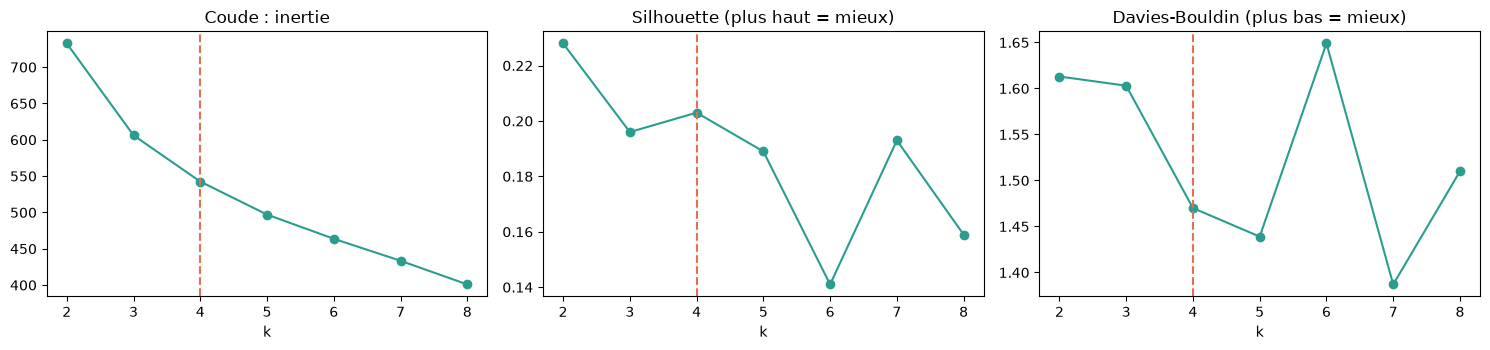

In [6]:
SILVER_MAIN_PATH = "/lakehouse/silver/flights_enriched"
GOLD_SEGMENTS_PATH = "/lakehouse/gold/segments_aeroports"

silver_df = spark.read.format("delta").load(SILVER_MAIN_PATH)

# Les 9 variables de l'ACP de J2 (étape 5), calculées par aéroport côté Spark (~100 lignes ramenées en pandas).
causes = ["air_system_delay", "weather_delay", "late_aircraft_delay", "airline_delay", "security_delay"]
total_causes = sum(F.coalesce(F.sum(c), F.lit(0)) for c in causes)
entities_sdf = (
    silver_df
    .where(F.col("airport_code_valid"))
    .groupBy("origin_airport")
    .agg(
        F.first("origin_city").alias("origin_city"),
        F.first("origin_state").alias("origin_state"),
        F.first("origin_lat").alias("origin_lat"),
        F.first("origin_lon").alias("origin_lon"),
        F.count("*").alias("nb_vols"),
        (100 * F.avg(F.col("is_delayed_15").cast("int"))).alias("taux_retard"),
        (100 * F.avg(F.col("is_cancelled").cast("int"))).alias("taux_annulation"),
        F.percentile_approx("taxi_out", 0.5).alias("roulage_median"),
        F.percentile_approx("distance", 0.5).alias("distance_mediane"),
        (100 * F.avg((F.col("dep_hour") >= 17).cast("int"))).alias("part_depart_soir"),
        (100 * F.sum("air_system_delay") / total_causes).alias("part_systeme"),
        (100 * F.sum("weather_delay") / total_causes).alias("part_meteo"),
        (100 * F.sum("late_aircraft_delay") / total_causes).alias("part_avion_retarde"),
        F.percentile_approx("arrival_delay", 0.9).alias("retard_p90_min"),  # pour le dashboard, hors K-Means
    )
    .where(F.col("nb_vols") >= 300)
)

entities_pd = entities_sdf.toPandas().dropna().copy()
entities_pd["log_trafic"] = np.log10(entities_pd["nb_vols"])  # trafic très asymétrique : en log, comme en J2

feature_cols = ["taux_retard", "taux_annulation", "roulage_median", "log_trafic", "distance_mediane",
                "part_depart_soir", "part_systeme", "part_meteo", "part_avion_retarde"]
print(f"{len(entities_pd)} aéroports avec au moins 300 vols, {len(feature_cols)} variables")
print("Asymétrie des variables :", entities_pd[feature_cols].skew().round(2).to_dict())

# Centrage-réduction : les variables n'ont pas les mêmes unités (%, minutes, miles, log)
X = StandardScaler().fit_transform(entities_pd[feature_cols])

# Choix de k : coude (inertie), silhouette (plus haut = mieux), Davies-Bouldin (plus bas = mieux)
ks = range(2, 9)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, random_state=42, n_init=20).fit(X)
    scores.append((k, km.inertia_, silhouette_score(X, km.labels_), davies_bouldin_score(X, km.labels_),
                   np.bincount(km.labels_).min()))
scores = pd.DataFrame(scores, columns=["k", "inertie", "silhouette", "davies_bouldin", "plus_petit_groupe"]).round(3)
print(scores.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, col, titre in zip(axes, ["inertie", "silhouette", "davies_bouldin"],
                          ["Coude : inertie", "Silhouette (plus haut = mieux)", "Davies-Bouldin (plus bas = mieux)"]):
    ax.plot(scores["k"], scores[col], "o-", color="#2A9D8F")
    ax.axvline(4, ls="--", color="#E76F51")
    ax.set_title(titre)
    ax.set_xlabel("k")
plt.tight_layout()
plt.show()

**Choix de k**

- **Le coude n'est pas net** : l'inertie baisse régulièrement de k = 2 à k = 8. Les profils d'aéroports varient de façon continue.
- **La silhouette est faible (0,19 à 0,23)** : avec 9 variables, les groupes se recouvrent en partie. C'est cohérent avec l'ACP de J2, où il fallait 4 axes pour résumer les aéroports.
- **L'indice de Davies-Bouldin baisse nettement de k = 3 (1,60) à k = 4 (1,47).** Il baisse encore un peu à k = 5 et k = 7, mais en ajoutant des groupes de 2 à 4 aéroports.
- On retient **k = 4**. Le 4e groupe est celui des aéroports exposés à la météo, que l'axe 3 de l'ACP laissait prévoir ; à k = 3, il est noyé dans les aéroports régionaux.

In [7]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=20)
entities_pd["cluster_id"] = kmeans.fit_predict(X).astype(int)

# Examiner les profils pour interpréter les groupes.
profile = entities_pd.groupby("cluster_id")[feature_cols + ["nb_vols"]].median()
profile["nb_aeroports"] = entities_pd.groupby("cluster_id").size()
display(profile.round(1).T)

# Nommer les groupes à partir de leur profil (règles indépendantes du numéro de cluster)
reste = list(profile.index)
hubs = profile.loc[reste, "log_trafic"].idxmax(); reste.remove(hubs)
meteo = profile.loc[reste, "part_meteo"].idxmax(); reste.remove(meteo)
cascade = profile.loc[reste, "part_avion_retarde"].idxmax(); reste.remove(cascade)
label_map = {
    hubs: "Grands hubs congestionnés",
    meteo: "Aéroports exposés à la météo",
    cascade: "Retards en cascade",
    reste[0]: "Aéroports régionaux perturbés",
}
entities_pd["segment"] = entities_pd["cluster_id"].map(label_map)

for seg, g in entities_pd.groupby("segment"):
    print(f"{seg} ({len(g)}) : {', '.join(g.nlargest(8, 'nb_vols')['origin_airport'])}")

assert entities_pd["segment"].notna().all()

(
    spark.createDataFrame(entities_pd)
    .coalesce(2)
    .write.format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .save(GOLD_SEGMENTS_PATH)
)

print(
    f"Table de segmentation enregistrée dans {GOLD_SEGMENTS_PATH} "
    f"({len(entities_pd):,} aéroports)"
)

cluster_id,0,1,2,3
taux_retard,18.9,16.8,17.4,20.4
taux_annulation,2.8,1.2,2.0,1.3
roulage_median,13.5,11.0,12.0,16.0
log_trafic,2.6,3.2,2.7,3.7
distance_mediane,507.5,583.0,524.0,853.0
part_depart_soir,12.7,26.5,21.3,31.7
part_systeme,20.4,17.4,25.6,24.5
part_meteo,16.7,3.3,3.7,3.9
part_avion_retarde,20.7,49.5,38.7,37.2
nb_vols,415.5,1484.0,498.5,5444.0


Aéroports exposés à la météo (4) : LIT, XNA, COS, FAT
Aéroports régionaux perturbés (42) : CLE, RDU, MKE, IND, PIT, CMH, PBI, CVG
Grands hubs congestionnés (25) : ATL, ORD, DFW, LAX, DEN, IAH, PHX, SFO
Retards en cascade (33) : MDW, SAN, TPA, DAL, HOU, PDX, BNA, STL


/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:659: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/opt/venv/lib/python3.15/site-packages/pyspark/sql/pandas/conversion.py:936: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


Table de segmentation enregistrée dans /lakehouse/gold/segments_aeroports (104 aéroports)


**Interprétation des segments**

| Segment | Aéroports | Profil (médianes) |
|---|---|---|
| **Grands hubs congestionnés** (25) | ATL, ORD, DFW, LAX, DEN, IAH, PHX, SFO | le plus de trafic (5 400 vols), roulage le plus long (16 min), vols longs (850 miles), 32 % de départs le soir, 20,4 % de retard |
| **Retards en cascade** (33) | MDW, SAN, TPA, DAL, HOU, PDX, BNA, STL, Hawaï | la moitié des minutes de retard vient d'un avion arrivé en retard (49 %), roulage court (11 min), 16,8 % de retard, 1,2 % d'annulations |
| **Aéroports régionaux perturbés** (42) | CLE, RDU, MKE, IND, PIT, CMH, PBI, CVG | peu de trafic (500 vols), la plus forte part de retard due au système aérien (26 %), 2,0 % d'annulations, 17,4 % de retard |
| **Aéroports exposés à la météo** (4) | LIT, XNA, COS, FAT | 17 % des minutes de retard dues à la météo (4 % ailleurs), le plus d'annulations (2,8 %), 18,9 % de retard |

- Les segments retrouvent les trois premiers axes de l'ACP de J2 : la congestion des hubs (axe 1), le retard propagé opposé aux perturbations du système aérien (axe 2), la météo (axe 3).
- **Un segment décrit la façon d'être en retard, pas seulement son niveau.** Atlanta est dans les hubs congestionnés par son trafic et son roulage, mais n'a que 17 % de retard. Dallas Love Field (base de Southwest) est dans les retards en cascade avec 23 %.
- Pour le voyageur : dans les hubs et les aéroports à retards en cascade, le risque monte au fil de la journée, il vaut mieux partir le matin. Dans les aéroports régionaux et ceux exposés à la météo, le risque est surtout l'annulation.

## 3. Livrable Final : Votre Application `app/dashboard.py` sur Streamlit (`:8501`)

Complétez maintenant **`app/dashboard.py`** pour valoriser vos tables `/lakehouse/gold/` :
- **Architecture respectée** : l'application Streamlit ne doit lire **que** des tables pré-calculées de la couche **Gold** (`/lakehouse/gold/...`), jamais les fichiers CSV bruts !
- **Interactivité** : au moins un filtre utilisateur (`st.selectbox`, `st.multiselect`, `st.slider`) et 3 à 4 visualisations Plotly Express complémentaires.
- **Rigueur explicative** : sous chaque visualisation clé, intégrez un `st.expander("Requête SQL & Justification statistique")` affichant la requête Spark SQL ayant produit la table Gold et justifiant le choix des indicateurs statistiques retenus.

In [8]:
# Vérification finale de l'inventaire complet de votre couche Gold sur HDFS
jvm = spark._jvm
fs = jvm.org.apache.hadoop.fs.FileSystem.get(spark._jsc.hadoopConfiguration())
PathHDFS = jvm.org.apache.hadoop.fs.Path
gold_root = PathHDFS("/lakehouse/gold")

gold_tables = [
    s.getPath().getName()
    for s in fs.listStatus(gold_root)
    if s.isDirectory() and fs.exists(PathHDFS(s.getPath(), "_delta_log"))
]
assert len(gold_tables) > 0, "Aucune table Delta trouvée dans /lakehouse/gold/ !"

print("=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===")
for t in sorted(gold_tables):
    cnt = spark.read.format("delta").load(f"/lakehouse/gold/{t}").count()
    print(f" - /lakehouse/gold/{t:<25} : {cnt:>9,} lignes")

=== Tables Delta disponibles dans /lakehouse/gold/ pour Streamlit ===


 - /lakehouse/gold/flight_replay             :     3,312 lignes


 - /lakehouse/gold/retards_mensuels          :        12 lignes


 - /lakehouse/gold/retards_par_compagnie     :        14 lignes


 - /lakehouse/gold/route_flows               :     3,754 lignes


 - /lakehouse/gold/segments_aeroports        :       104 lignes


 - /lakehouse/gold/stats_tests               :         4 lignes


 - /lakehouse/gold/top_compagnie_retards_par_aeroport :       103 lignes
